# Cats and Dogs Classification

Classify images as cat or dog using transfer learning in PyTorch, comparing ResNet-18 and EfficientNet-B0.

- **Dataset:** [Kaggle – Dog and Cat Classification Dataset](https://www.kaggle.com/datasets/bhavikjikadara/dog-and-cat-classification-dataset)
- **Target:** Cat or Dog
- **Main metrics:** accuracy and ROC-AUC, supported by PR-AUC and macro F1
- **Baseline:** 50% accuracy, because the classes are balanced
- **Final model:** ResNet-18, with a test accuracy of 98.6% and ROC-AUC of 0.999

# 1. Setup

Install PyTorch and the other packages, import the libraries, and set the image size, batch size and random seed.

In [ ]:
%pip install -U pip
%pip uninstall -y torch torchvision
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu134
%pip install -q -r requirements.txt

In [2]:
from pathlib import Path
import os
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import copy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             classification_report, f1_score, roc_auc_score, roc_curve)
from torch import nn
from torchvision import models

In [3]:
RANDOM_SEED = 42
DATA_FOLDER = Path.cwd() / "data"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
torch.manual_seed(RANDOM_SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Training on:", device)

Training on: cuda


# 2. Load data

Load the images with PyTorch. `ImageFolderSkipHidden` skips hidden folders such as `.ipynb_checkpoints`, so they are not treated as classes.

In [4]:
# ImageFolder that ignores hidden folders such as .ipynb_checkpoints.
class ImageFolderSkipHidden(datasets.ImageFolder):

    def find_classes(self, directory):
        class_names = sorted(entry.name for entry in os.scandir(directory)
                             if entry.is_dir() and not entry.name.startswith("."))
        return class_names, {class_name: index for index, class_name in enumerate(class_names)}

## Transforms and class balance

Training images are resized, augmented with flips, rotation and color jitter, then normalized with ImageNet statistics. Validation and test images are resized and normalized the same way, without augmentation, so the model sees the same input scale at every stage.

In [5]:
training_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])
evaluation_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])


training_source = ImageFolderSkipHidden(DATA_FOLDER, transform=training_transform)
evaluation_source = ImageFolderSkipHidden(DATA_FOLDER, transform=evaluation_transform)
print(training_source.class_to_idx)

labels = np.array(training_source.targets)
print("Images per class:", np.bincount(labels)) # Print the total number of classes to see if the dataset is balanced or not

{'Cat': 0, 'Dog': 1}
Images per class: [12499 12499]


## Train, validation and test split

Images are split 70/15/15 with stratification, giving 17,498 training, 3,750 validation and 3,750 test images.

In [6]:
# Split positions 70(train) / 15(validation) / 15(testing)
all_positions = np.arange(len(labels))
train_positions, other_positions = train_test_split(
    all_positions, test_size=0.30, stratify=labels, random_state=RANDOM_SEED)
validation_positions, test_positions = train_test_split(
    other_positions, test_size=0.50, stratify=labels[other_positions], random_state=RANDOM_SEED)

train_dataset = Subset(training_source, train_positions)              # augmented
validation_dataset = Subset(evaluation_source, validation_positions)  # not augmented
test_dataset = Subset(evaluation_source, test_positions)              # not augmented

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

## Check the splits

Preview a batch from each split to confirm that only the training images are augmented. Titles show the class (0 = Cat, 1 = Dog). Colors look unusual because the previews show normalized values.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2391288].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7240347..2.5702832].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7582842..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9295317..2.4482791].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9295317..1.2805231].
Cli

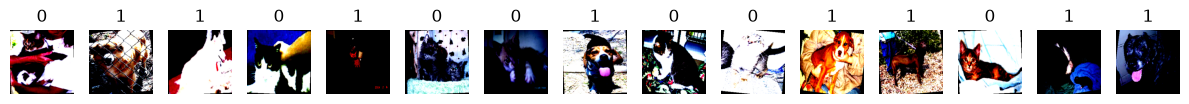

17498


In [7]:
train_images, batch_labels = next(iter(train_loader))

# Plot the 15 images
plt.figure(figsize=(12, 4))
for i in range(15):
    img = train_images[i]
    # Handle grayscale vs RGB
    if img.shape[0] == 1:  # Grayscale
        plt.subplot(1, 15, i+1)
        plt.imshow(img.squeeze(), cmap="gray")
    else:  # RGB
        plt.subplot(1, 15, i+1)
        plt.imshow(img.permute(1, 2, 0))  # C,H,W -> H,W,C
    plt.axis("off")
    plt.title(str(batch_labels[i].item()))
plt.tight_layout()
plt.show()

print(len(train_dataset.indices))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..2.2739873].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2391288].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9481792..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0357141..2.1519828].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0182073..1.9951199].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0494049..2.5877128].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.6

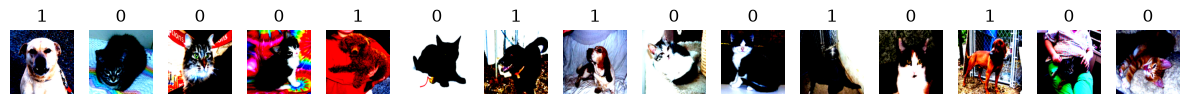

3750


In [8]:
validation_images, batch_labels = next(iter(validation_loader))

# Plot the 15 images
plt.figure(figsize=(12, 4))
for i in range(15):
    img = validation_images[i]
    # Handle grayscale vs RGB
    if img.shape[0] == 1:  # Grayscale
        plt.subplot(1, 15, i+1)
        plt.imshow(img.squeeze(), cmap="gray")
    else:  # RGB
        plt.subplot(1, 15, i+1)
        plt.imshow(img.permute(1, 2, 0))  # C,H,W -> H,W,C
    plt.axis("off")
    plt.title(str(batch_labels[i].item()))
plt.tight_layout()
plt.show()

print(len(validation_dataset.indices))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9656862..1.4782944].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0836544..2.2914162].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9980307..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7925336..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8956583..1.7685405].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7347276..2.64].
Clippi

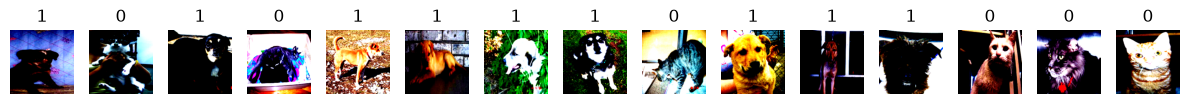

3750


In [9]:
test_images, batch_labels = next(iter(test_loader))

# Plot the 15 images
plt.figure(figsize=(12, 4))
for i in range(15):
    img = test_images[i]
    # Handle grayscale vs RGB
    if img.shape[0] == 1:  # Grayscale
        plt.subplot(1, 15, i+1)
        plt.imshow(img.squeeze(), cmap="gray")
    else:  # RGB
        plt.subplot(1, 15, i+1)
        plt.imshow(img.permute(1, 2, 0))  # C,H,W -> H,W,C
    plt.axis("off")
    plt.title(str(batch_labels[i].item()))
plt.tight_layout()
plt.show()

print(len(test_dataset.indices))

# 3. Modeling and Evaluation

ResNet-18 and EfficientNet-B0 start from ImageNet-pretrained weights and are trained in two stages.

## Training settings

| Stage | Trainable layers | Learning rate | Maximum epochs |
|---|---|---|---|
| 1. Feature extraction | New output layer only | 1e-3 | 10 |
| 2. Fine-tuning | Output layer and top block | 1e-4 | 10 |

Early stopping ends a stage after 3 epochs without improvement in validation loss. The learning rate is 10 times smaller in stage 2 to protect the pretrained weights.

In [10]:
class_names = list(training_source.class_to_idx)          # index 1 = the "positive" class
MAXIMUM_EPOCHS_STAGE_1 = 10                               # train new output layer only
MAXIMUM_EPOCHS_STAGE_2 = 10                               # fine-tune top block
EARLY_STOPPING_PATIENCE = 3                               # epochs without improvement
LEARNING_RATE_STAGE_1 = 1e-3
LEARNING_RATE_STAGE_2 = 1e-4                              # 10x smaller: protect pretrained weights

# Class weights from the TRAINING images only ("balanced" formula)
train_class_counts = np.bincount(labels[train_positions], minlength=len(class_names))
class_weights = len(train_positions) / (len(class_names) * train_class_counts)
loss_function = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32,
                                                        device=device))
print("Training images per class:", dict(zip(class_names, train_class_counts)))

Training images per class: {'Cat': np.int64(8749), 'Dog': np.int64(8749)}


## Model, training and evaluation functions

- `build_model` loads a pretrained model, replaces its output layer and freezes the backbone.
- `run_one_epoch` runs one pass over a data loader, and only updates weights when given an optimizer.
- `train_with_early_stopping` trains one stage and restores the best weights.
- `train_two_stages` runs feature extraction, then fine-tuning.
- `predict_probabilities` and `evaluate_model` score a model on a data loader.

In [11]:
# Build a pretrained model with a new output layer
def build_model(model_name, number_of_classes):
    if model_name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, number_of_classes)
        output_layer, top_block = model.fc, model.layer4
    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, number_of_classes)
        output_layer, top_block = model.classifier, model.features[-1]
    else:
        raise ValueError(f"Unknown model name: {model_name}")

    for parameter in model.parameters():
        parameter.requires_grad = False                   # freeze the pretrained backbone
    for parameter in output_layer.parameters():
        parameter.requires_grad = True                    # train only the new output layer
    return model.to(device), top_block


# Training helpers functions
def run_one_epoch(model, data_loader, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss = 0.0
    with torch.set_grad_enabled(is_training):
        for images, batch_labels in data_loader:
            images, batch_labels = images.to(device), batch_labels.to(device)
            loss = loss_function(model(images), batch_labels)
            if is_training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(batch_labels)
    return total_loss / len(data_loader.dataset)


def train_with_early_stopping(model, optimizer, maximum_epochs, stage):
    best_validation_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    history = []
    for epoch in range(1, maximum_epochs + 1):
        train_loss = run_one_epoch(model, train_loader, optimizer)
        validation_loss = run_one_epoch(model, validation_loader)
        history.append({"stage": stage, "epoch": epoch,
                        "train_loss": train_loss, "validation_loss": validation_loss})
        print(f"stage {stage} epoch {epoch}: train {train_loss:.4f} | validation {validation_loss:.4f}")

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f"Early stop: no improvement for {EARLY_STOPPING_PATIENCE} epochs")
                break
    model.load_state_dict(best_weights)
    return history


def train_two_stages(model_name):
    model, top_block = build_model(model_name, len(class_names))

    trainable_parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.AdamW(trainable_parameters, lr=LEARNING_RATE_STAGE_1)
    history = train_with_early_stopping(model, optimizer, MAXIMUM_EPOCHS_STAGE_1, stage=1)

    for parameter in top_block.parameters():          # Stage 2 Unfreeze the top layer
        parameter.requires_grad = True
    trainable_parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.AdamW(trainable_parameters, lr=LEARNING_RATE_STAGE_2)
    history += train_with_early_stopping(model, optimizer, MAXIMUM_EPOCHS_STAGE_2, stage=2)

    return model, pd.DataFrame(history)


# Evaluation helpers functions
def predict_probabilities(model, data_loader):
    model.eval()
    true_label_batches, probability_batches = [], []
    with torch.no_grad():
        for images, batch_labels in data_loader:
            class_probabilities = torch.softmax(model(images.to(device)), dim=1)
            probability_batches.append(class_probabilities[:, 1].cpu())
            true_label_batches.append(batch_labels)
    return torch.cat(true_label_batches).numpy(), torch.cat(probability_batches).numpy()


def evaluate_model(model_name, model, data_loader, threshold=0.5):
    true_labels, positive_probabilities = predict_probabilities(model, data_loader)
    predicted_labels = (positive_probabilities >= threshold).astype(int)
    return {
        "model": model_name,
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "roc_auc": roc_auc_score(true_labels, positive_probabilities),
        "pr_auc": average_precision_score(true_labels, positive_probabilities),
        "macro_f1": f1_score(true_labels, predicted_labels, average="macro"),
    }

In [12]:
# Train both models
trained_models, training_histories = {}, {}
for model_name in ["resnet18", "efficientnet_b0"]:
    print(f"\n===== {model_name} =====")
    trained_models[model_name], training_histories[model_name] = train_two_stages(model_name)


===== resnet18 =====


C:\Users\User\anaconda3\envs\Data-Science-Projects\Lib\site-packages\PIL\TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


stage 1 epoch 1: train 0.1388 | validation 0.0715
stage 1 epoch 2: train 0.0949 | validation 0.0670
stage 1 epoch 3: train 0.0969 | validation 0.0868
stage 1 epoch 4: train 0.0926 | validation 0.0636
stage 1 epoch 5: train 0.0902 | validation 0.0702
stage 1 epoch 6: train 0.0901 | validation 0.0662
stage 1 epoch 7: train 0.0861 | validation 0.0640
Early stop: no improvement for 3 epochs
stage 2 epoch 1: train 0.0823 | validation 0.0407
stage 2 epoch 2: train 0.0469 | validation 0.0328
stage 2 epoch 3: train 0.0314 | validation 0.0395
stage 2 epoch 4: train 0.0242 | validation 0.0336
stage 2 epoch 5: train 0.0223 | validation 0.0398
Early stop: no improvement for 3 epochs

===== efficientnet_b0 =====
stage 1 epoch 1: train 0.1865 | validation 0.0948
stage 1 epoch 2: train 0.1359 | validation 0.0874
stage 1 epoch 3: train 0.1323 | validation 0.0829
stage 1 epoch 4: train 0.1258 | validation 0.0843
stage 1 epoch 5: train 0.1277 | validation 0.0854
stage 1 epoch 6: train 0.1290 | validatio

## Learning curves

Training and validation loss across both stages. The dashed line marks the start of fine-tuning.

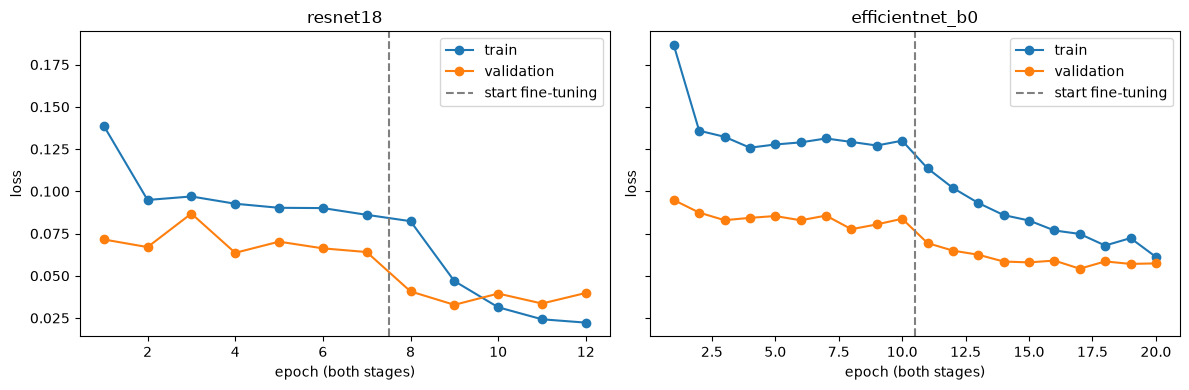

In [13]:
# Learning curves: a widening gap between the lines means overfitting
figure, axes = plt.subplots(1, len(training_histories), figsize=(12, 4), sharey=True)
for axis, (model_name, history) in zip(np.atleast_1d(axes), training_histories.items()):
    step = np.arange(1, len(history) + 1)
    axis.plot(step, history["train_loss"], marker="o", label="train")
    axis.plot(step, history["validation_loss"], marker="o", label="validation")
    stage_2_start = (history["stage"] == 2).idxmax() + 1
    axis.axvline(stage_2_start - 0.5, color="grey", linestyle="--", label="start fine-tuning")
    axis.set(title=model_name, xlabel="epoch (both stages)", ylabel="loss")
    axis.legend()
plt.tight_layout()
plt.show()

**Findings:**

- Fine-tuning lowers the loss for both models. ResNet-18 reaches its best validation loss of 0.0328 in stage 2, and EfficientNet-B0 reaches 0.0542.
- Validation loss sits below training loss for most of training, likely because training images are augmented and validation images are not.
- Late in fine-tuning, ResNet-18's training loss falls below its validation loss, an early sign of overfitting. Early stopping ends training there and restores the best weights.

## Compare models on the validation set

The model with the best validation ROC-AUC is chosen.

In [14]:
# Compare on the VALIDATION set and choose a model
validation_labels = labels[validation_positions]
majority_class_accuracy = np.bincount(validation_labels).max() / len(validation_labels)
print(f"Baseline (always predict the biggest class): accuracy {majority_class_accuracy:.3f}, ROC-AUC 0.500")

validation_results = pd.DataFrame([evaluate_model(name, model, validation_loader)
                                   for name, model in trained_models.items()]).set_index("model")
print(validation_results.round(3))

best_model_name = validation_results["roc_auc"].idxmax()
best_model = trained_models[best_model_name]
print("Chosen on validation ROC-AUC:", best_model_name)

Baseline (always predict the biggest class): accuracy 0.500, ROC-AUC 0.500
                 accuracy  roc_auc  pr_auc  macro_f1
model                                               
resnet18            0.986    0.999   0.999     0.986
efficientnet_b0     0.980    0.998   0.998     0.980
Chosen on validation ROC-AUC: resnet18


**Result:** both models are well above the 0.500 baseline, and the margin between them is small. ResNet-18 is chosen.

| Model | Accuracy | ROC-AUC | PR-AUC | Macro F1 |
|---|---|---|---|---|
| ResNet-18 | 0.986 | 0.999 | 0.999 | 0.986 |
| EfficientNet-B0 | 0.980 | 0.998 | 0.998 | 0.980 |

## Final check on the test set

Only the chosen model is evaluated on the test set.

accuracy    0.986
roc_auc     0.999
pr_auc      0.999
macro_f1    0.986
dtype: object
              precision    recall  f1-score   support

         Cat      0.988     0.985     0.986      1875
         Dog      0.985     0.988     0.986      1875

    accuracy                          0.986      3750
   macro avg      0.986     0.986     0.986      3750
weighted avg      0.986     0.986     0.986      3750



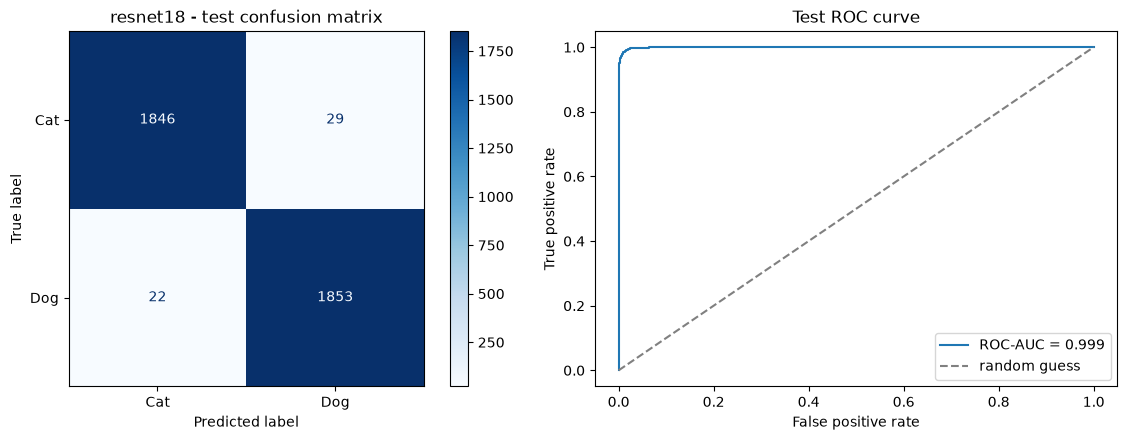

In [15]:
# Final check on the TEST set - run once to test the model on unseen data.
test_labels, test_probabilities = predict_probabilities(best_model, test_loader)
test_predictions = (test_probabilities >= 0.5).astype(int)
print(pd.Series(evaluate_model(best_model_name, best_model, test_loader)).drop("model").round(3))
print(classification_report(test_labels, test_predictions, target_names=class_names, digits=3))

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(test_labels, test_predictions, display_labels=class_names,
                                        cmap="Blues", ax=axes[0])
axes[0].set_title(f"{best_model_name} - test confusion matrix")
false_positive_rate, true_positive_rate, _ = roc_curve(test_labels, test_probabilities)
axes[1].plot(false_positive_rate, true_positive_rate,
             label=f"ROC-AUC = {roc_auc_score(test_labels, test_probabilities):.3f}")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="random guess")
axes[1].set(title="Test ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend()
plt.tight_layout()
plt.show()

**Result:** ResNet-18 reaches 98.6% accuracy and 0.999 ROC-AUC on the test set, matching its validation results. It misclassifies 51 of 3,750 images: 29 cats as dogs and 22 dogs as cats.

## Save the model

The checkpoint stores the model weights, class mapping, image size and PyTorch version.

In [16]:
# Save the chosen model
torch.save({"model_name": best_model_name,
            "state_dict": best_model.state_dict(),
            "class_to_idx": training_source.class_to_idx,
            "image_size": IMAGE_SIZE,
            "torch_version": str(torch.__version__)},
           f"{best_model_name}_best.pt")

# 4. Inference Test

Reload the saved checkpoint, apply the same preprocessing as the evaluation images, and classify new images from `testing_images/`.

In [17]:
from pathlib import Path
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torchvision import models, transforms

In [18]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
device = "cuda" if torch.cuda.is_available() else "cpu"
TESTING_IMAGE_FOLDER = Path.cwd() / "testing_images"
IMAGE_SIZE = (224, 224) 
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

In [19]:
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)
checkpoint = torch.load("resnet18_best.pt", map_location=device, weights_only=True)
model.load_state_dict(checkpoint['state_dict'])
model.to(device).eval()   # important for inference

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [20]:
def predict_image(predictor, image_path):
    with Image.open(image_path) as image:
        image_tensor = predictor["image_transform"](image.convert("RGB")).unsqueeze(0).to(device)
    with torch.inference_mode():                         # no gradients: faster, less memory
        class_probabilities = torch.softmax(predictor["model"](image_tensor), dim=1)[0].cpu()
    predicted_index = int(class_probabilities.argmax())
    return {
        "image": str(image_path),
        "prediction": predictor["index_to_class"][predicted_index],
        "probability": round(float(class_probabilities[predicted_index]), 4)
    }

In [21]:
image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

index_to_class = {index: class_name for class_name, index in checkpoint["class_to_idx"].items()}

predictor = {
    "model": model, 
    "model_name": checkpoint["model_name"],
    "index_to_class": index_to_class, 
    "image_transform": image_transform
}

image_paths = sorted(path for path in TESTING_IMAGE_FOLDER.rglob("*") if path.suffix.lower() in IMAGE_EXTENSIONS)

results = pd.DataFrame([predict_image(predictor, path) for path in image_paths])
results.to_csv("predictions.csv", index=False)
print(results.to_string(index=False))
print(f"\nSaved {len(results)} predictions to predictions.csv")

                                                                                     image prediction  probability
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\image1.jpg        Cat       1.0000
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\image2.jpg        Cat       1.0000
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\image3.jpg        Cat       1.0000
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\image4.jpg        Dog       1.0000
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\image5.jpg        Dog       0.9689
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\image6.jpg        Dog       1.0000
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\image7.jpg        Dog       1.0000
C:\Users\User\Data Science Projects\Cats and Dogs Classification\testing_images\

**Result:** the model predicts four cats and four dogs. Seven predictions have a confidence of 1.000 after rounding, and `image5.jpg` is at 0.969.

# 5. Conclusion

ResNet-18 is the final model, with 98.6% test accuracy and 0.999 ROC-AUC against a 50% baseline. EfficientNet-B0 is very close behind.

**Next steps:**

- **Error analysis:** review the 51 misclassified test images for label errors and hard cases.
- **Reproducibility:** seed NumPy and the data loaders as well as PyTorch.